# 05 · Error analysis and interpretability

Where does the default model (PLS(31)) go wrong, and what has it learned?

1. Out-of-fold predictions: every face is predicted by a model that never saw its person
2. Overall accuracy with person-level bootstrap confidence intervals, and calibration
3. Errors by expression, database and label angle
4. Interpretation: distance weights, variable importance, and the facial movements behind each
   output and each PLS component

Full scripts: `experiments/10_error_analysis.py` and `experiments/11_interpretability.py`.
This notebook uses the original images only (no mirrored copies, which are predicted equally
well). Runtime: about 2 minutes.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
ROOT = Path.cwd() if (Path.cwd() / "examples").is_dir() else Path.cwd().parent  # repo root

from sklearn.cross_decomposition import PLSRegression

from facial_expression_analysis import Frontalizer
from facial_expression_analysis.features import PairwiseDistanceFeatures
from facial_expression_analysis.training.data import load_morphset
from facial_expression_analysis.training.evaluation import (
    bootstrap_ci,
    pls_path,
    repeated_group_kfold,
)
from facial_expression_analysis.training.interpret import (
    equivalent_movement,
    movement_region_shares,
    plot_movement,
    plot_pair_weights,
    pls_vip,
    region_shares,
    standardized_coefficients,
)
from facial_expression_analysis.training.metrics import ccc

TARGETS = ("arousal", "valence", "intensity")

## 1. Out-of-fold predictions

In [2]:
%%time
data = load_morphset()
orig = ~data.meta.mirrored.to_numpy()
meta = data.meta[orig].reset_index(drop=True)
y, persons = data.targets[orig], data.persons[orig]
frontal = Frontalizer()(data.landmarks[orig])
feats = PairwiseDistanceFeatures()
X = feats(frontal)
oof = np.zeros_like(y)
for f in repeated_group_kfold(persons, n_splits=5, seed=0):
    oof[f.test] = pls_path(X[f.train], y[f.train], 31).predict(X[f.test])[-1]
oof[:, :2] = np.clip(oof[:, :2], -1, 1)
oof[:, 2] = np.clip(oof[:, 2], 0, 1)

CPU times: user 1min 50s, sys: 887 ms, total: 1min 51s
Wall time: 1min 49s


## 2. Accuracy, uncertainty and calibration

Confidence intervals resample **persons** (not faces), because faces of the same person are
strongly correlated. The calibration slope is the slope of prediction on target: below 1 means
predictions are compressed towards the mean.

In [3]:
rows = []
for k, t in enumerate(TARGETS):
    est, lo, hi = bootstrap_ci(y[:, k], oof[:, k], persons, n_boot=300)
    rows.append(
        {
            "target": t,
            "CCC": est,
            "95% CI": f"[{lo:.3f}, {hi:.3f}]",
            "calibration slope": np.polyfit(y[:, k], oof[:, k], 1)[0],
        }
    )
pd.DataFrame(rows).set_index("target").round(3)

,CCC,95% CI,calibration slope
target,,,
arousal,0.630,"[0.612, 0.650]",0.471
valence,0.805,"[0.793, 0.818]",0.683
intensity,0.661,"[0.648, 0.677]",0.498


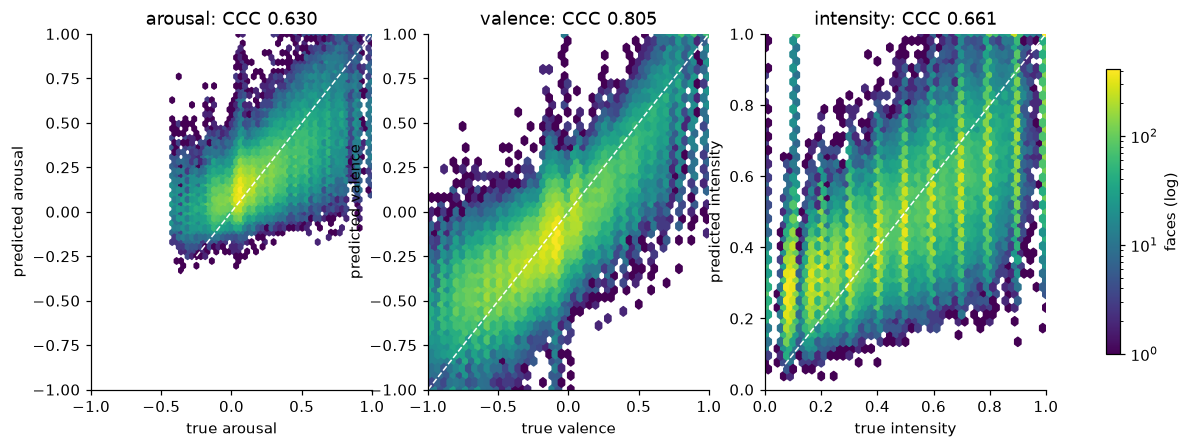

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (k, t) in zip(axes, enumerate(TARGETS), strict=True):
    lim = (0, 1) if t == "intensity" else (-1, 1)
    hb = ax.hexbin(y[:, k], oof[:, k], gridsize=45, bins="log", cmap="viridis", mincnt=1)
    ax.plot(lim, lim, "w--", lw=1)
    ax.set(
        xlim=lim,
        ylim=lim,
        xlabel=f"true {t}",
        ylabel=f"predicted {t}",
        title=f"{t}: CCC {ccc(y[:, k], oof[:, k]):.3f}",
    )
fig.colorbar(hb, ax=axes, shrink=0.8, label="faces (log)");

The model is unbiased on average but **shrinks**: strong expressions are under-predicted and
neutral faces get an intensity of about 0.3 instead of 0. This is typical of least-squares
models on noisy features. A global rescaling would raise CCC, but it also amplifies jitter, so it
is not applied (see the model card).

## 3. Where are the errors?

Mean error (bias = predicted − true) by expression and by source database.

label,AF,AN,AN_DI,DI,DI_SA1,DI_SA2,DI_SA3,HA,HA_SU1,HA_SU2,HA_SU3,NE,SA,SU,SU_AF
arousal bias,-0.187,-0.205,-0.135,-0.028,0.028,0.093,0.169,0.068,0.006,-0.028,-0.019,0.108,0.262,0.023,-0.073
valence bias,0.022,-0.064,-0.028,0.022,0.094,0.138,0.152,-0.187,-0.146,-0.168,-0.147,-0.140,0.141,-0.076,-0.039
intensity bias,-0.015,-0.043,0.001,0.069,0.022,-0.021,-0.056,0.043,0.014,-0.001,0.015,0.314,-0.066,0.044,0.030


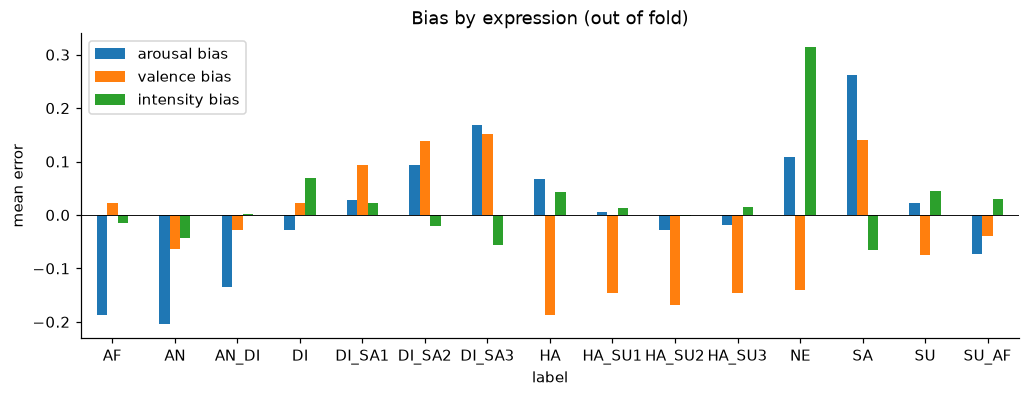

In [5]:
df = meta[["dataset", "label"]].copy()
for k, t in enumerate(TARGETS):
    df[f"{t} bias"] = oof[:, k] - y[:, k]
    df[f"{t} |err|"] = np.abs(oof[:, k] - y[:, k])
by_label = df.groupby("label", observed=True)[[f"{t} bias" for t in TARGETS]].mean()
ax = by_label.plot.bar(figsize=(11, 3.6), rot=0)
ax.axhline(0, color="k", lw=0.6)
ax.set(ylabel="mean error", title="Bias by expression (out of fold)")
by_label.round(3).T

In [6]:
by_db = df.groupby("dataset", observed=True)[[f"{t} |err|" for t in TARGETS]].mean()
by_db.index = by_db.index.map({"R": "RaFD", "K": "KDEF", "W": "WSEFEP", "F": "FACES"})
print("Mean absolute error by source database")
by_db.round(3)

Mean absolute error by source database


,arousal |err|,valence |err|,intensity |err|
dataset,,,
FACES,0.190,0.207,0.174
KDEF,0.136,0.178,0.141
RaFD,0.130,0.155,0.129
WSEFEP,0.120,0.136,0.134


In [7]:
pred_angle = np.degrees(np.arctan2(oof[:, 0], oof[:, 1])) % 360
strong = np.hypot(oof[:, 0], oof[:, 1]) > 0.1
outside = strong & (pred_angle > 215) & (pred_angle < 355)
print(
    f"predictions in the 215°–355° range, where there are no training labels: {outside.mean():.2%}"
)

predictions in the 215°–355° range, where there are no training labels: 0.43%


- **Sad** faces are read as too aroused, and **anger** and **fear** as not aroused enough. Their
  geometric cues overlap with neighbouring expressions.
- **FACES** (which includes older adults) has the largest errors.
- The model almost never predicts the calm/sleepy quadrant, because MorphSet has no labels
  there (notebook 01).

## 4. What has the model learned?

Fit PLS(31) on all faces and look at it in three ways.

,arousal,valence,intensity
mouth,0.172,0.232,0.180
eyes-mouth,0.105,0.171,0.145
mouth-nose,0.100,0.137,0.111
brows-mouth,0.146,0.103,0.118
eyes-nose,0.091,0.095,0.109
eyes,0.098,0.077,0.103
brows-eyes,0.155,0.076,0.119
brows,0.045,0.045,0.044


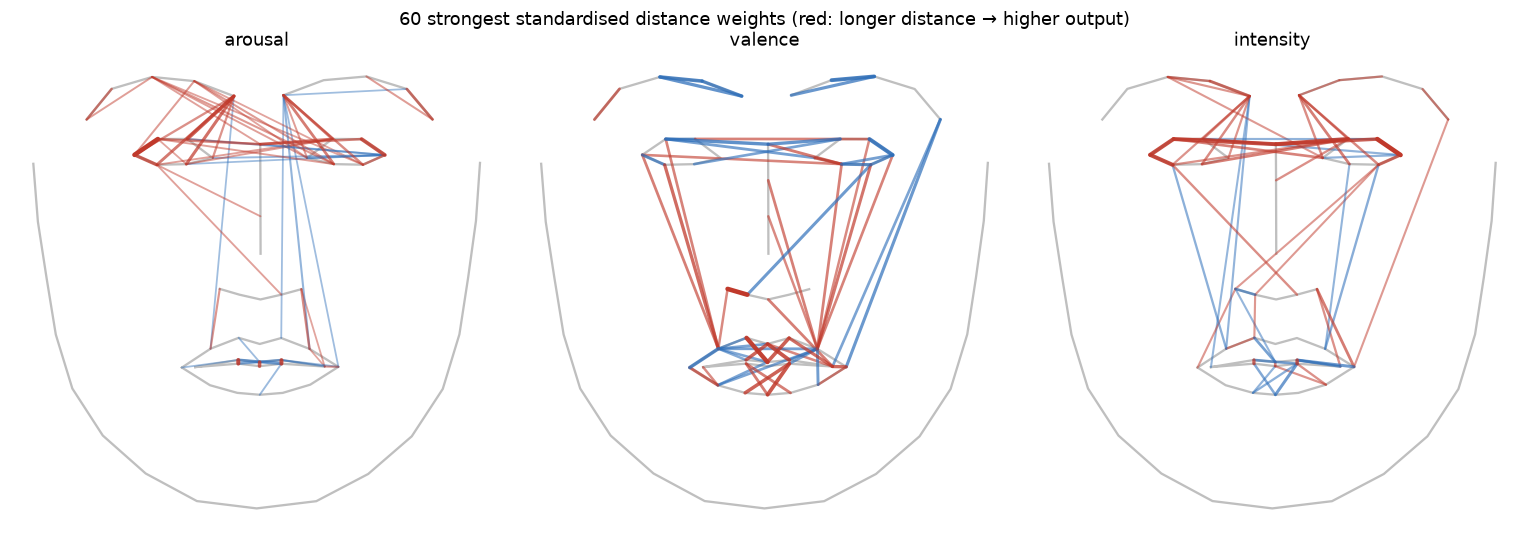

In [8]:
pls = PLSRegression(31).fit(X, y)
coef = np.asarray(pls.coef_).T if pls.coef_.shape[0] == 3 else np.asarray(pls.coef_)
std_coef = standardized_coefficients(coef, X)
pairs = feats.pairs
mean_face = frontal[(meta.label == "NE").to_numpy()].mean(0)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (k, t) in zip(axes, enumerate(TARGETS), strict=True):
    plot_pair_weights(ax, mean_face, pairs, std_coef[:, k], top=60, title=t)
fig.suptitle("60 strongest standardised distance weights (red: longer distance → higher output)")
plt.tight_layout()
pd.DataFrame({t: region_shares(std_coef[:, k], pairs) for k, t in enumerate(TARGETS)}).fillna(
    0
).sort_values("valence", ascending=False).head(8).round(3)

In [9]:
vip = pls_vip(pls)
top = np.argsort(-vip)[:10]
print("Top-10 distances by variable importance in projection (VIP > 1 = above average):")
pd.DataFrame({"landmarks": [f"{a}–{b}" for a, b in pairs[top]], "VIP": vip[top]}).round(
    2
).set_index("landmarks")

Top-10 distances by variable importance in projection (VIP > 1 = above average):


,VIP
landmarks,
48–60,2.29
54–64,2.11
59–67,1.98
55–65,1.86
48–67,1.67
60–67,1.66
54–65,1.65
27–40,1.63
64–65,1.63


The top distances are all around the inner mouth corners (48–60, 54–64), which open and stretch
with almost every expression.

Individual weights are hard to read: many distances share landmarks and are strongly correlated,
so large weights partly cancel. The strongest arousal weights sit around the eyes and brows, yet
the next view shows that what actually accompanies a higher arousal prediction is mostly the
mouth. To get that view, regress the frontalized landmarks on each prediction across all faces:
the slope is the facial movement that accompanies one unit more of that output.

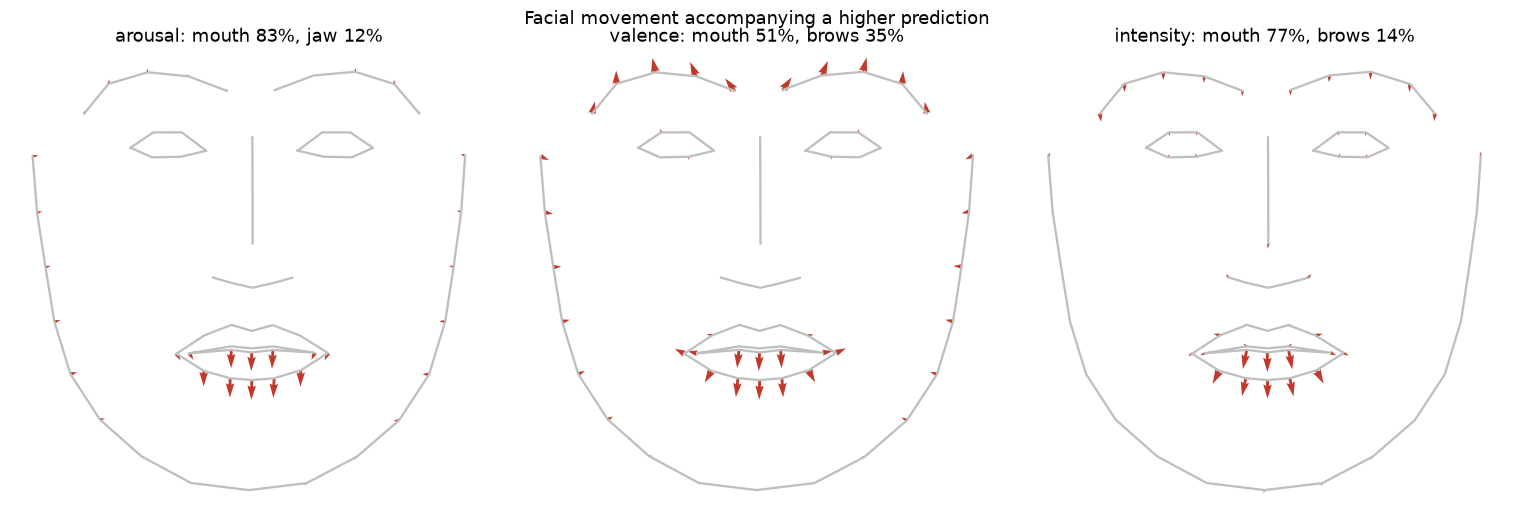

In [10]:
pred = pls.predict(X)
L = frontal.reshape(len(frontal), -1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (k, t) in zip(axes, enumerate(TARGETS), strict=True):
    yt = pred[:, k] - pred[:, k].mean()
    move = ((L - L.mean(0)).T @ yt / (yt @ yt)).reshape(68, 2)
    top2 = movement_region_shares(move).sort_values(ascending=False).head(2)
    plot_movement(
        ax, mean_face, move, title=f"{t}: " + ", ".join(f"{r} {v:.0%}" for r, v in top2.items())
    )
fig.suptitle("Facial movement accompanying a higher prediction")
plt.tight_layout()

- **Arousal** is mostly mouth opening, which is why talking or yawning reads as aroused.
- **Valence** is the lip corners moving out and up, with raised brows.
- **Intensity** is overall mouth activity.

### Are the PLS components facial action units?

Each component is a direction in distance space. Converted to the smallest landmark movement
that produces it, many turn out to be localised, like action units.

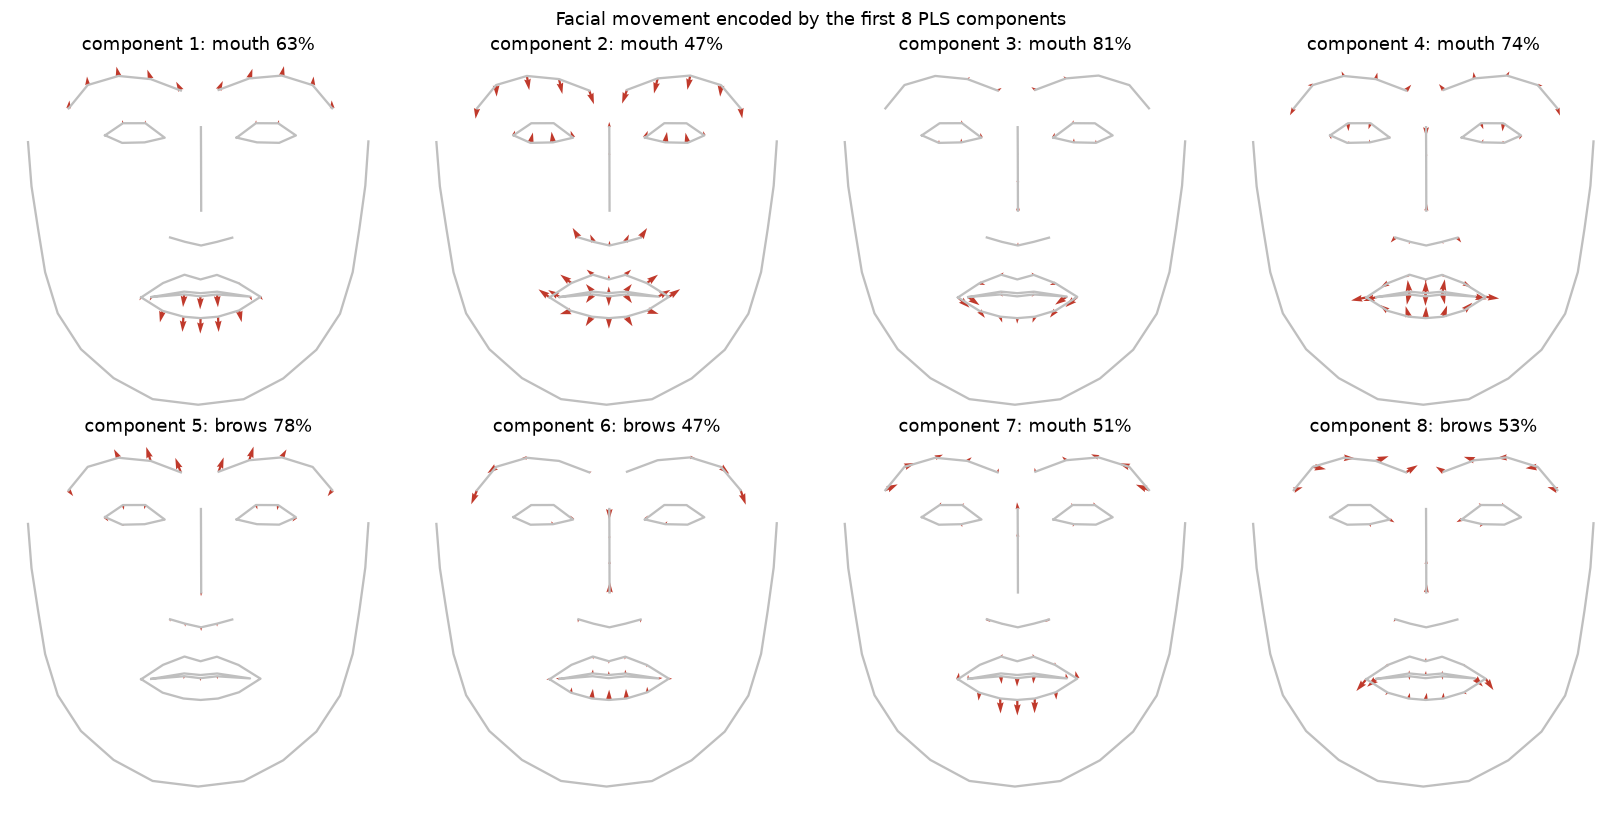

In [11]:
x_std = X.std(axis=0, dtype=np.float64)
loadings = pls.x_loadings_ * x_std[:, None]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for c, ax in enumerate(axes.ravel()):
    move = equivalent_movement(loadings[:, c], mean_face, pairs)
    shares = movement_region_shares(move)
    plot_movement(
        ax, mean_face, move, title=f"component {c + 1}: {shares.idxmax()} {shares.max():.0%}"
    )
fig.suptitle("Facial movement encoded by the first 8 PLS components")
plt.tight_layout()

The first components separate mouth opening (1), lip stretching (2, 4), lip-corner movement (3, 7)
and brow raising or lowering (5, 6, 8): interpretable building blocks, roughly like action units. `experiments/11` tests
this against random directions: 17 of the 31 components are more localised than chance.

**Summary of the series:** the data (01), pose removal (02), features and model selection
(03), retraining and export (04), and this analysis together reproduce every number in the
README and the model card.